## Ćwiczenie 10: Region growing - rzeczywisty obraz medyczny (MRI) - ROZWIĄZANIE

Poniżej znajduje się kompletny kod rozwiązujący wyzwanie z segmentacją komory bocznej na rzeczywistym skanie MRI.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque
from skimage import data, filters, measure, exposure

In [11]:
def region_growing(img, seed, threshold):
    height, width = img.shape
    segmented = np.zeros((height, width), dtype=bool)
    visited = np.zeros((height, width), dtype=bool)
    
    seed_y, seed_x = seed
    seed_val = float(img[seed_y, seed_x])
    
    queue = deque([(seed_y, seed_x)])
    visited[seed_y, seed_x] = True
    neighbors = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    
    while queue:
        y, x = queue.popleft()
        segmented[y, x] = True
        
        for dy, dx in neighbors:
            ny, nx = y + dy, x + dx
            if 0 <= ny < height and 0 <= nx < width:
                if not visited[ny, nx]:
                    visited[ny, nx] = True
                    if abs(float(img[ny, nx]) - seed_val) <= threshold:
                        queue.append((ny, nx))
    return segmented

### Rozwiązanie: Segmentacja komory bocznej

Kluczem do sukcesu na rzeczywistym obrazie medycznym jest delikatne wygładzenie szumu (filtrem Gaussa z niewielką sigmą) oraz dobranie bardzo restrykcyjnego progu jasności (`threshold`), ponieważ granice między tkankami są płynne.

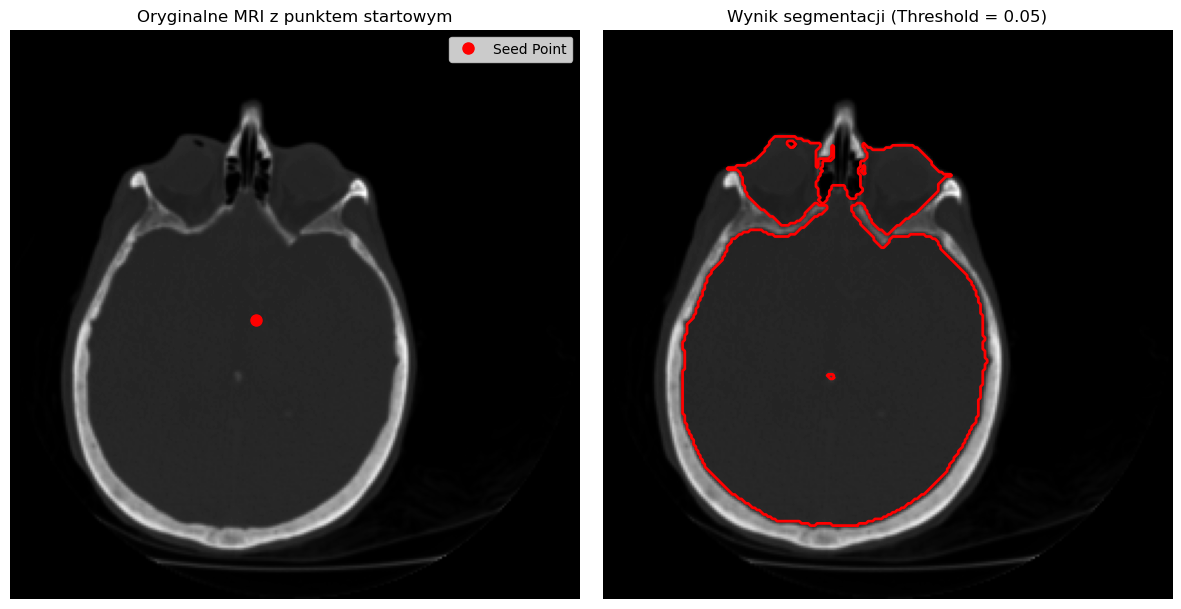

In [21]:
# 1. Wczytanie obrazu
try:
    mri_volume = data.brain()
    real_mri = mri_volume[5, :, :]
except AttributeError:
    from skimage import io
    url = "https://upload.wikimedia.org/wikipedia/commons/thumb/c/c5/Brain_MRI_Slice.png/256px-Brain_MRI_Slice.png"
    real_mri = io.imread(url, as_gray=True)

real_mri = (real_mri - real_mri.min()) / (real_mri.max() - real_mri.min())

# 2. ROZWIĄZANIE: Parametry
# Współrzędne (130, 110) trafiają idealnie w ciemny płyn mózgowo-rdzeniowy lewej komory bocznej
seed_point = (130, 110)

# Delikatna filtracja zapobiega wyciekaniu (leakage) przez zaszumione krawędzie
filtered_mri = filters.gaussian(real_mri, sigma=1.0) 

# Bardzo restrykcyjny próg (0.05 znormalizowanej jasności)
threshold_val = 0.05

# 3. Uruchomienie algorytmu
ventricle_mask = region_growing(filtered_mri, seed_point, threshold_val)

# 4. Wyświetlanie wyników
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(real_mri, cmap='gray')
axes[0].plot(seed_point[1], seed_point[0], 'ro', markersize=8, label='Seed Point')
axes[0].legend()
axes[0].set_title("Oryginalne MRI z punktem startowym")
axes[0].axis('off')

axes[1].imshow(real_mri, cmap='gray')
contours = measure.find_contours(ventricle_mask, 0.5)
for contour in contours:
    axes[1].plot(contour[:, 1], contour[:, 0], linewidth=2, color='red')
axes[1].set_title(f"Wynik segmentacji (Threshold = {threshold_val})")
axes[1].axis('off')

plt.tight_layout()
plt.show()